# 04 — Model training

XGBoost, Random Forest and Ridge on each branch, tuned by search over a
TimeSeriesSplit of the training period only. The test period, January 2022 to
December 2024, is evaluated once. Scores: RMSE, R² and MAE.

Input: `data/processed/features_*.csv` · Output: `results/04_*`

In [1]:
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import loguniform, randint, uniform
from sklearn.base import clone
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, TimeSeriesSplit
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from xgboost import XGBRegressor

BRANCHES = ["original", "seasonal", "trend"]
SUFFIX = {"original": "", "seasonal": "_S", "trend": "_T"}
data = {b: pd.read_csv(f"../data/processed/features_{b}.csv",
                       index_col="date", parse_dates=True) for b in BRANCHES}


def split(df):
    X = df.drop(columns=["target", "split"])
    train = df["split"] == "train"
    return X[train], X[~train], df.loc[train, "target"], df.loc[~train, "target"]


for b, df in data.items():
    Xtr, Xte, ytr, yte = split(df)
    print(f"{b:9s} {Xtr.shape[1]:2d} features | "
          f"train {len(Xtr)} ({Xtr.index.min():%Y-%m}..{Xtr.index.max():%Y-%m}) | "
          f"test {len(Xte)} ({Xte.index.min():%Y-%m}..{Xte.index.max():%Y-%m})")

original  14 features | train 238 (2002-03..2021-12) | test 36 (2022-01..2024-12)
seasonal  17 features | train 238 (2002-03..2021-12) | test 36 (2022-01..2024-12)
trend      6 features | train 238 (2002-03..2021-12) | test 36 (2022-01..2024-12)


## Hyperparameter tuning

Randomised search (100 draws) for the tree models, grid search over 101 penalties
for Ridge, all scored by mean squared error on a five-fold TimeSeriesSplit of the
training period. Ridge is standardised inside its pipeline, so scaling uses training
statistics only. Any tuned value within 5% of the edge of its range is reported,
since a value on the edge means the search wanted to go further.

In [2]:
SEED = 0
CV = TimeSeriesSplit(n_splits=5)
N_ITER = 100

# Ranges wide enough that no tuned value should sit on an edge; at_edge() below
# reports any that does.
MODELS = {
    "XGBoost": (XGBRegressor(random_state=SEED, n_jobs=1), {
        "n_estimators": randint(100, 3001), "max_depth": randint(1, 9),
        "learning_rate": loguniform(0.0005, 0.3), "subsample": uniform(0.3, 0.7),
        "colsample_bytree": uniform(0.3, 0.7), "min_child_weight": randint(1, 21),
        "reg_lambda": loguniform(0.01, 100)}),
    "RandomForest": (RandomForestRegressor(random_state=SEED, n_jobs=1), {
        "n_estimators": randint(200, 1000), "max_depth": [None, 2, 3, 4, 6, 8, 12, 16],
        "min_samples_leaf": randint(1, 21), "max_features": ["sqrt", 0.33, 0.5, 0.75, 1.0]}),
    "Ridge": (make_pipeline(StandardScaler(), Ridge()), {
        "ridge__alpha": np.logspace(-6, 4, 101)}),
}


def tune(name, X, y):
    est, space = MODELS[name]
    if name == "Ridge":
        search = GridSearchCV(est, space, cv=CV,
                              scoring="neg_mean_squared_error", n_jobs=-1)
    else:
        search = RandomizedSearchCV(est, space, n_iter=N_ITER, cv=CV,
                                    scoring="neg_mean_squared_error",
                                    random_state=SEED, n_jobs=-1)
    return search.fit(X, y)


def at_edge(name, params):
    """Tuned values within 5% (log scale for rates) of the edge of their range."""
    hits = []
    for k, v in params.items():
        dist = MODELS[name][1][k]
        if isinstance(dist, list) or not isinstance(v, (int, float)):
            vals = list(dist)
            if v in (vals[0], vals[-1]) and len(vals) > 2:
                hits.append(f"{k}={v}")
            continue
        if hasattr(dist, "support"):
            lo, hi = dist.support()
        else:
            lo, hi = min(dist), max(dist)
        log = k in ("learning_rate", "reg_lambda", "ridge__alpha")
        f = (np.log(v) - np.log(lo)) / (np.log(hi) - np.log(lo)) if log else (v - lo) / (hi - lo)
        if f < 0.05 or f > 0.95:
            hits.append(f"{k}={v:.4g}")
    return hits


best_params, cv_rmse = {}, {}
for b, df in data.items():
    Xtr, _, ytr, _ = split(df)
    for name in MODELS:
        search = tune(name, Xtr, ytr)
        best_params[(b, name)] = search.best_params_
        cv_rmse[(b, name)] = np.sqrt(-search.best_score_)
        edge = at_edge(name, search.best_params_)
        print(f"{b:9s} {name:12s} CV RMSE {cv_rmse[(b, name)]:.4f}   "
              f"at an edge: {', '.join(edge) if edge else 'none'}")

original  XGBoost      CV RMSE 0.0480   at an edge: max_depth=8


original  RandomForest CV RMSE 0.0495   at an edge: none


original  Ridge        CV RMSE 0.0523   at an edge: none


seasonal  XGBoost      CV RMSE 0.0437   at an edge: colsample_bytree=0.3082, n_estimators=2950


seasonal  RandomForest CV RMSE 0.0470   at an edge: none


seasonal  Ridge        CV RMSE 0.0424   at an edge: none


trend     XGBoost      CV RMSE 0.0064   at an edge: reg_lambda=0.01358, subsample=0.9878


trend     RandomForest CV RMSE 0.0059   at an edge: max_depth=None, max_features=1.0


trend     Ridge        CV RMSE 0.0020   at an edge: ridge__alpha=1e-06


## Test period

Two baselines alongside the models. **Persistence** predicts last month's value.
**Climatology** predicts the training-period mean for the calendar month.

In [3]:
def make_model(b, name, seed=SEED):
    est = clone(MODELS[name][0]).set_params(**best_params[(b, name)])
    if name != "Ridge":
        est.set_params(random_state=seed)
    return est


def scores(y, p):
    return dict(RMSE=np.sqrt(mean_squared_error(y, p)), R2=r2_score(y, p),
                MAE=mean_absolute_error(y, p))


def baselines(b, df, test_mask):
    y = df["target"]
    persistence = df[f"NDVI{SUFFIX[b]}_lag1"]
    clim = y[~test_mask].groupby(y[~test_mask].index.month).mean()
    climatology = pd.Series(y.index.month.map(clim), index=y.index)
    return {"persistence": persistence, "climatology": climatology}


rows, predictions = [], {}
for b, df in data.items():
    Xtr, Xte, ytr, yte = split(df)
    test = df["split"] == "test"
    for name in MODELS:
        p = make_model(b, name).fit(Xtr, ytr).predict(Xte)
        predictions[(b, name)] = pd.Series(p, index=Xte.index)
        rows.append(dict(branch=b, model=name, **scores(yte, p)))
    for name, s in baselines(b, df, test).items():
        predictions[(b, name)] = s[test]
        rows.append(dict(branch=b, model=name, **scores(yte, s[test])))

test_scores = pd.DataFrame(rows)
ORDER = ["XGBoost", "RandomForest", "Ridge", "persistence", "climatology"]
for metric in ["RMSE", "R2", "MAE"]:
    print(f"\n{metric}")
    print(test_scores.pivot(index="model", columns="branch", values=metric)
                     .loc[ORDER, BRANCHES].round(4).to_string())


RMSE
branch        original  seasonal   trend
model                                   
XGBoost         0.0536    0.0553  0.0091
RandomForest    0.0583    0.0570  0.0062
Ridge           0.0597    0.0587  0.0021
persistence     0.0972    0.0971  0.0021
climatology     0.0751    0.0733  0.0404

R2
branch        original  seasonal   trend
model                                   
XGBoost         0.8839    0.8732  0.7998
RandomForest    0.8623    0.8655  0.9078
Ridge           0.8560    0.8574  0.9896
persistence     0.6179    0.6092  0.9893
climatology     0.7719    0.7774 -2.9469

MAE
branch        original  seasonal   trend
model                                   
XGBoost         0.0368    0.0401  0.0080
RandomForest    0.0373    0.0392  0.0052
Ridge           0.0470    0.0459  0.0018
persistence     0.0697    0.0696  0.0017
climatology     0.0472    0.0481  0.0349


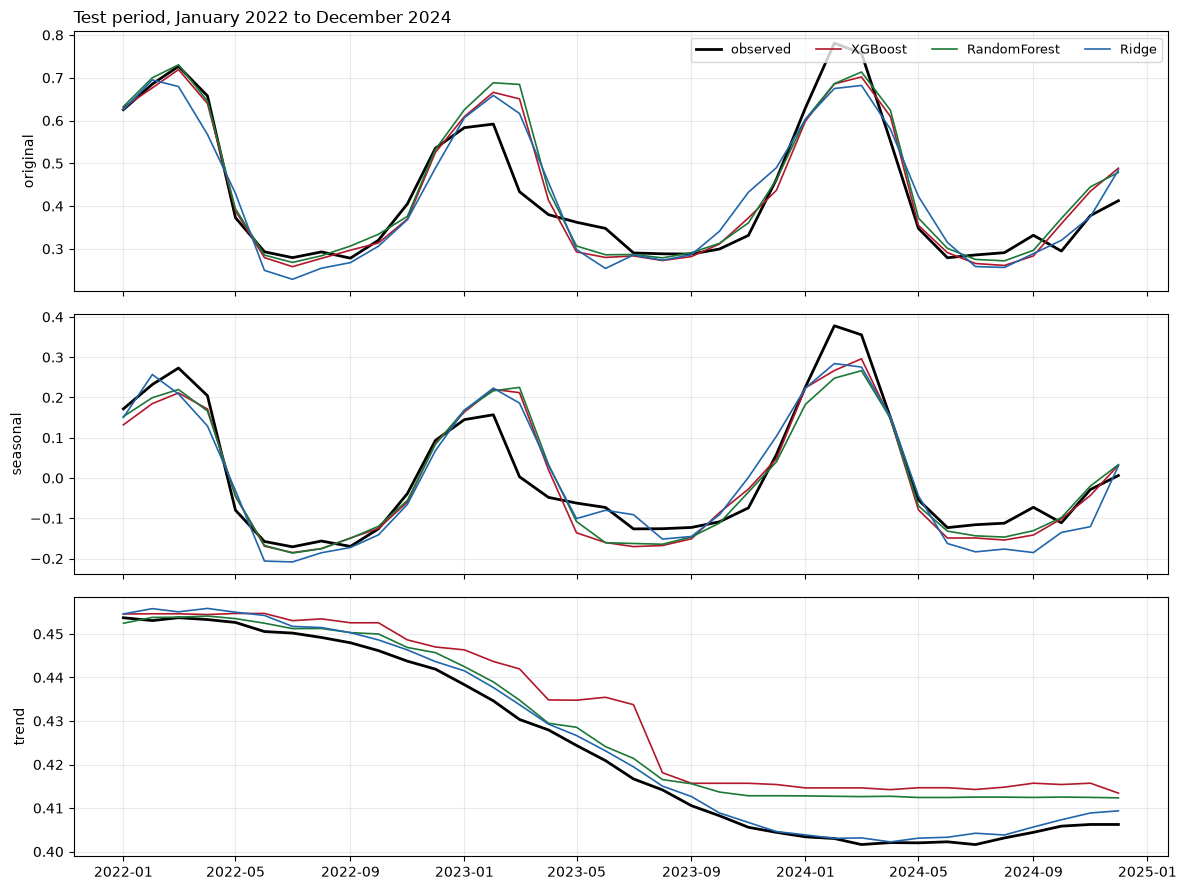

In [4]:
fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
colors = {"XGBoost": "#b2182b", "RandomForest": "#1b7837", "Ridge": "#2166ac"}
for ax, b in zip(axes, BRANCHES):
    _, Xte, _, yte = split(data[b])
    ax.plot(yte.index, yte, color="black", lw=2, label="observed")
    for name, c in colors.items():
        ax.plot(yte.index, predictions[(b, name)], color=c, lw=1.2, label=name)
    ax.set_ylabel(b)
    ax.grid(alpha=0.25)
axes[0].legend(ncol=4, loc="upper right", fontsize=9)
axes[0].set_title("Test period, January 2022 to December 2024", loc="left")
fig.tight_layout()
fig.savefig("../figures/04_test_predictions.png", dpi=150, bbox_inches="tight")
plt.show()

## Noise floor

Each tree model refitted with 20 seeds at its tuned parameters. A difference smaller
than the seed-to-seed standard deviation is indistinguishable from refitting. Ridge
is deterministic.

In [5]:
floor = []
for b, df in data.items():
    Xtr, Xte, ytr, yte = split(df)
    for name in MODELS:
        seeds = [SEED] if name == "Ridge" else range(20)
        runs = [scores(yte, make_model(b, name, s).fit(Xtr, ytr).predict(Xte)) for s in seeds]
        floor.append(dict(branch=b, model=name,
                          RMSE_mean=np.mean([r["RMSE"] for r in runs]),
                          RMSE_sd=np.std([r["RMSE"] for r in runs]),
                          R2_mean=np.mean([r["R2"] for r in runs]),
                          R2_sd=np.std([r["R2"] for r in runs])))

noise_floor = pd.DataFrame(floor)
print(noise_floor.round(4).to_string(index=False))

  branch        model  RMSE_mean  RMSE_sd  R2_mean  R2_sd
original      XGBoost     0.0539   0.0004   0.8824 0.0019
original RandomForest     0.0584   0.0005   0.8619 0.0022
original        Ridge     0.0597   0.0000   0.8560 0.0000
seasonal      XGBoost     0.0548   0.0004   0.8757 0.0019
seasonal RandomForest     0.0573   0.0003   0.8641 0.0013
seasonal        Ridge     0.0587   0.0000   0.8574 0.0000
   trend      XGBoost     0.0089   0.0011   0.8065 0.0461
   trend RandomForest     0.0061   0.0000   0.9094 0.0011
   trend        Ridge     0.0021   0.0000   0.9896 0.0000


## Rolling-origin evaluation

Five consecutive three-year test windows, each model trained on everything before
its window. Each of the four earlier windows is tuned again, by the same search, on
its own training years only, so no window is scored with settings chosen on data
that includes it. The last window is the test period and keeps the tuning above.

In [6]:
WINDOWS = [("2010-01-01", "2012-12-01"), ("2013-01-01", "2015-12-01"),
           ("2016-01-01", "2018-12-01"), ("2019-01-01", "2021-12-01"),
           ("2022-01-01", "2024-12-01")]

# Each window is tuned again on its own training years, so no window is scored with
# settings chosen on data that includes it. The last window is the test period and
# keeps the tuning above, which used the same training years.
window_params, folds = {}, []
for b, df in data.items():
    X, y = df.drop(columns=["target", "split"]), df["target"]
    for start, end in WINDOWS:
        tr, te = df.index < start, (df.index >= start) & (df.index <= end)
        label = start[:4] + "-" + end[2:4]
        for name in MODELS:
            if start == WINDOWS[-1][0]:
                params = best_params[(b, name)]
            else:
                params = tune(name, X[tr], y[tr]).best_params_
            window_params[(b, label, name)] = params
            est = clone(MODELS[name][0]).set_params(**params)
            p = est.fit(X[tr], y[tr]).predict(X[te])
            folds.append(dict(branch=b, window=label, model=name,
                              RMSE=np.sqrt(mean_squared_error(y[te], p)),
                              R2=r2_score(y[te], p)))
        for name, s in baselines(b, df, ~tr).items():
            folds.append(dict(branch=b, window=start[:4] + "-" + end[2:4], model=name,
                              RMSE=np.sqrt(mean_squared_error(y[te], s[te])),
                              R2=r2_score(y[te], s[te])))

rolling = pd.DataFrame(folds)
order = ["XGBoost", "RandomForest", "Ridge", "persistence", "climatology"]
for b in BRANCHES:
    for metric, digits in [("RMSE", 4), ("R2", 3)]:
        t = rolling[rolling.branch == b].pivot(index="model", columns="window",
                                               values=metric).loc[order]
        t["mean"], t["sd"] = t.mean(axis=1), t.std(axis=1)
        print(f"\n{b} — {metric}"); print(t.round(digits).to_string())


original — RMSE
window        2010-12  2013-15  2016-18  2019-21  2022-24    mean      sd
model                                                                    
XGBoost        0.0601   0.0373   0.0453   0.0377   0.0536  0.0468  0.0100
RandomForest   0.0613   0.0328   0.0455   0.0411   0.0583  0.0478  0.0120
Ridge          0.0608   0.0436   0.0491   0.0422   0.0597  0.0511  0.0088
persistence    0.0999   0.1034   0.1098   0.1012   0.0972  0.1023  0.0048
climatology    0.0758   0.0357   0.0581   0.0522   0.0751  0.0594  0.0168

original — R2
window        2010-12  2013-15  2016-18  2019-21  2022-24   mean     sd
model                                                                  
XGBoost         0.872    0.948    0.938    0.954    0.884  0.919  0.038
RandomForest    0.867    0.960    0.937    0.945    0.862  0.914  0.046
Ridge           0.870    0.929    0.927    0.942    0.856  0.905  0.039
persistence     0.648    0.602    0.635    0.666    0.618  0.634  0.025
climatology     0.

## Reconstruction

Seasonal plus trend predictions, compared with the model fitted to the original
series directly.

In [7]:
y_orig = split(data["original"])[3]
recon = []
for name in MODELS:
    p = (predictions[("seasonal", name)] + predictions[("trend", name)]).reindex(y_orig.index)
    direct = test_scores.query("branch == 'original' and model == @name").iloc[0]
    recon.append(dict(model=name,
                      RMSE_direct=direct.RMSE, RMSE_reconstructed=np.sqrt(mean_squared_error(y_orig, p)),
                      R2_direct=direct.R2, R2_reconstructed=r2_score(y_orig, p)))
print(pd.DataFrame(recon).round(4).to_string(index=False))

       model  RMSE_direct  RMSE_reconstructed  R2_direct  R2_reconstructed
     XGBoost       0.0536              0.0542     0.8839            0.8810
RandomForest       0.0583              0.0558     0.8623            0.8741
       Ridge       0.0597              0.0586     0.8560            0.8613


## Saving

In [8]:
json.dump({f"{b}|{m}": {k: (v.item() if hasattr(v, "item") else v) for k, v in p.items()}
           for (b, m), p in best_params.items()},
          open("../results/04_best_params.json", "w"), indent=2)
test_scores.to_csv("../results/04_test_scores.csv", index=False)
noise_floor.to_csv("../results/04_noise_floor.csv", index=False)
rolling.to_csv("../results/04_rolling_origin.csv", index=False)
json.dump({f"{b}|{w}|{m}": {k: (v.item() if hasattr(v, "item") else v) for k, v in p.items()}
           for (b, w, m), p in window_params.items()},
          open("../results/04_window_params.json", "w"), indent=2)
pd.DataFrame({f"{b}|{m}": s for (b, m), s in predictions.items()}) \
  .to_csv("../results/04_test_predictions.csv")
print("saved")

saved
